# Geometry Processing, Streamlines, and Discrete Operators

This notebook demonstrates the new meshio++ geometry and discrete-operator capabilities:

- **Streamlines** (`streamlines`) on a 3-D rotational flow field
- **Curve-skeleton extraction** (`extract_skeleton`) on a torus
- **Shortest geodesic paths & geodesic Voronoi** (`shortest_path`, `geodesic_voronoi`)
- **Feature-preserving surface denoising** (`denoise_surface`)
- **FFD & RBF deformation** (`deform_ffd`, `deform_rbf`)
- **FVM quality** (`compute_fvm_quality`), **inter-mesh transfer operators** (`transfer_operator`), and **spectral shape descriptors** (`spectral_descriptors`)

Streamlines: 6197 points, 6185 segments
Skeleton: 24 nodes, mean radius=0.242
Shortest path length: 3.129 (analytic pi=3.142)
FVM interior faces: 540, HKS scales: 6


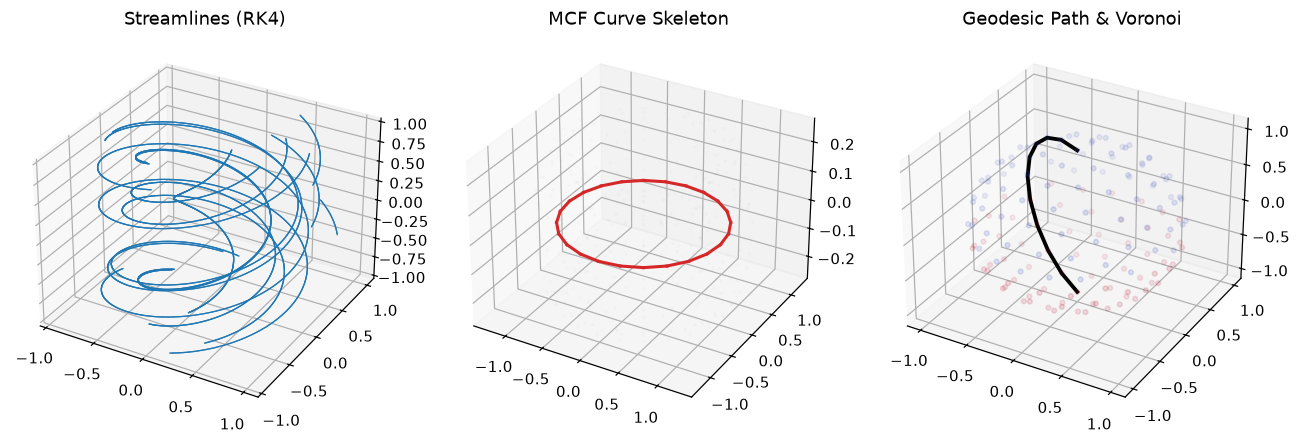

In [1]:
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import meshioplusplus as mio

# 1. Streamlines on a rotational 3-D flow
box = mio.box(dims=(6, 6, 6), size=(2.0, 2.0, 2.0), origin=(-1.0, -1.0, -1.0))
pts = box.points
vel = np.column_stack([-pts[:, 1], pts[:, 0], 0.25 * np.ones(len(pts))])
box.point_data['U'] = vel
lines = mio.streamlines(box, array='U', seeds=12, max_length=2.5)
print(f'Streamlines: {len(lines.points)} points, {sum(len(c.data) for c in lines.cells)} segments')

# 2. Curve-skeleton on a triangulated torus
tor = mio.torus(major_radius=1.0, minor_radius=0.25, nu=24, nv=14, cell_type='triangle')
skel, sk_rep = mio.extract_skeleton(tor, max_iterations=10, return_report=True)
print(f'Skeleton: {sk_rep["num_nodes"]} nodes, mean radius={np.mean(skel.point_data["skeleton:radius"]):.3f}')

# 3. Shortest geodesic path & Voronoi on a sphere
sph = mio.icosa_sphere(radius=1.0, subdivisions=2)
src, dst = int(np.argmax(sph.points[:, 2])), int(np.argmin(sph.points[:, 2]))
path, sp_rep = mio.shortest_path(sph, source=src, target=dst, method='heat_trace', return_report=True)
vor = mio.geodesic_voronoi(sph, sources=[src, dst])
print(f'Shortest path length: {sp_rep["total_length"]:.3f} (analytic pi={np.pi:.3f})')

# 4. Spectral descriptors (HKS) & FVM quality
hks_mesh, hks_rep = mio.spectral_descriptors(sph, kind='hks', num_modes=12, num_scales=6, return_report=True)
fvm = mio.compute_fvm_quality(box)
print(f'FVM interior faces: {fvm["num_interior_faces"]}, HKS scales: {len(hks_rep["scales"])}')

fig = plt.figure(figsize=(12, 4))
ax1 = fig.add_subplot(131, projection='3d')
lp = lines.points
for seg in lines.cells[0].data:
    ax1.plot(lp[seg, 0], lp[seg, 1], lp[seg, 2], color='tab:blue', lw=0.8)
ax1.set_title('Streamlines (RK4)')

ax2 = fig.add_subplot(132, projection='3d')
ax2.scatter(tor.points[:, 0], tor.points[:, 1], tor.points[:, 2], s=2, alpha=0.15, color='gray')
sp = skel.points
for seg in skel.cells[0].data:
    ax2.plot(sp[seg, 0], sp[seg, 1], sp[seg, 2], color='tab:red', lw=2.0)
ax2.set_title('MCF Curve Skeleton')

ax3 = fig.add_subplot(133, projection='3d')
ax3.scatter(sph.points[:, 0], sph.points[:, 1], sph.points[:, 2], c=vor.point_data['geodesic:nearest_source'], s=10, cmap='coolwarm', alpha=0.4)
pp = path.points
ax3.plot(pp[:, 0], pp[:, 1], pp[:, 2], color='black', lw=2.5)
ax3.set_title('Geodesic Path & Voronoi')
plt.tight_layout()
plt.show()
